# 20 — Prior mismatch and the realistic base rate

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 58 and 59.

* **A. Prior mismatch.** The fresh-injection CNN (notebook 07) was trained on sine-Gaussians with f₀ = 50–400 Hz, Q = 4–15, pulses with σ = 0.8–5 ms, chirps with f₀ = 50–150 Hz, ḟ = 150–600 Hz/s, and SNR 3–15. It and the 160-template bank are tested on injections *outside* those ranges (f₀, Q, σ, ḟ, and loud signals up to ρ = 40), at the FAP 10⁻² threshold of the validation noise. The bank was designed for f₀ = 40–450 Hz and Q = 3–16, so it is partly outside its design range too: the question is who degrades more.
* **B. Base rate.** The efficiencies of this project are for a balanced problem. With an astrophysical prior probability π per one-second window, the probability that an alarm is a real signal is PPV = ε π / (ε π + FAP (1 − π)). We tabulate it for single-detector FAP 10⁻² / 10⁻³ and for the two-detector FAP 10⁻⁶ of notebook 09, and the FAP needed for PPV = 0.5 and 0.9, at several event rates.

**What it does not do.** No retraining on wider priors (that is the remedy, not tested here); the event rates are *illustrative assumptions* (not measured burst rates) and ε is the efficiency of the pipeline at a given optimal SNR.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
rng = np.random.default_rng(20)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]])
NETS = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
B160 = {i: g.SGBank(CH[i]["S1"]) for i in CH}
d = np.load(os.path.join(g.CACHE, "scan03_val.npz")); BANK_VAL = d["rho2"]; CNN_VAL = logit(V["val"])
THR = {"bank": g.threshold_at_far(BANK_VAL, 1e-2), "cnn": g.threshold_at_far(CNN_VAL, 1e-2)}
U = lambda lo, hi, n: rng.uniform(lo, hi, n); LU = lambda lo, hi, n: np.exp(rng.uniform(np.log(lo), np.log(hi), n))
CASES = {   # name: (morphology, parameter overrides)
    "sg in prior (f0 50-400, Q 4-15)": ("sg", {}),
    "sg f0 400-500 Hz": ("sg", {"f0": lambda n: U(400, 500, n)}),
    "sg f0 30-50 Hz": ("sg", {"f0": lambda n: U(30, 50, n)}),
    "sg Q 20-40 (narrow band)": ("sg", {"Q": lambda n: U(20, 40, n)}),
    "sg Q 1.5-3.5 (broad band)": ("sg", {"Q": lambda n: U(1.5, 3.5, n)}),
    "pulse in prior (0.8-5 ms)": ("pulse", {}),
    "pulse 0.3-0.8 ms": ("pulse", {"sigma": lambda n: LU(0.3e-3, 0.8e-3, n)}),
    "pulse 5-15 ms": ("pulse", {"sigma": lambda n: LU(5e-3, 15e-3, n)}),
    "chirp in prior": ("chirp", {}),
    "chirp steeper (fdot 600-1500)": ("chirp", {"fdot": lambda n: U(600, 1500, n)}),
    "chirp f0 150-250 Hz": ("chirp", {"f0": lambda n: U(150, 250, n)}),
}
SNR_A = [4, 6, 8, 10, 14, 20, 30, 40]; NINJ = 400

## A. Prior mismatch

In [2]:
fn = os.path.join(g.CACHE, "stats20.pkl")
if os.path.exists(fn):
    RES = pickle.load(open(fn, "rb"))
else:
    RES = {}
    for name, (kind, ov) in CASES.items():
        for snr in SNR_A:
            i = rng.choice(len(V["test"]), NINJ, replace=False); p = g.draw_params(kind, rng, NINJ)
            for k, f in ov.items(): p[k] = f(NINJ)
            ser, _, _ = g.inject(V["test"][i], kind, float(snr), rng, S1te[i], params=p)
            RES[(name, snr)] = dict(bank=g.scan_mixed(ser, ID["test"][i], B160)["rho2"], cnn=logit(ser))
    pickle.dump(RES, open(fn, "wb"))
rows = []
for name in CASES:
    for det, thr in THR.items():
        e = [float((RES[(name, s)][det] > thr).mean()) for s in SNR_A]
        rows.append(dict(case=name, detector=det, **{f"eff@{s}": v for s, v in zip(SNR_A, e)}, rho50=g.snr_level(e, SNR_A, .5)))
A = pd.DataFrame(rows); P = A.pivot(index="case", columns="detector", values="rho50").loc[list(CASES)]
E8 = A.pivot(index="case", columns="detector", values="eff@8").loc[list(CASES)]; E40 = A.pivot(index="case", columns="detector", values="eff@40").loc[list(CASES)]
pd.concat({"rho50": P, "eff at rho=8": E8, "eff at rho=40": E40}, axis=1).round(2)

rho50       eff at rho=8       eff at rho=40  \
detector                         bank   cnn         bank   cnn          bank   
case                                                                           
sg in prior (f0 50-400, Q 4-15)  4.94  4.65         1.00  0.99           1.0   
sg f0 400-500 Hz                 5.09  8.62         0.99  0.42           1.0   
sg f0 30-50 Hz                   5.66  6.68         0.82  0.62           1.0   
sg Q 20-40 (narrow band)         5.42  5.28         0.97  0.90           1.0   
sg Q 1.5-3.5 (broad band)        5.05  4.61         1.00  0.98           1.0   
pulse in prior (0.8-5 ms)        5.30  4.00         1.00  1.00           1.0   
pulse 0.3-0.8 ms                 5.49  4.49         0.98  0.99           1.0   
pulse 5-15 ms                    6.71  9.33         0.70  0.49           1.0   
chirp in prior                   6.31  4.57         0.88  0.99           1.0   
chirp steeper (fdot 600-1500)    6.99  4.87         0.77  0.98           1.0   
chirp f0 150-250 Hz              6.97  7.40         0.74  0.57           1.0   

                                       
detector                          cnn  
case                                   
sg in prior (f0 50-400, Q 4-15)  1.00  
sg f0 400-500 Hz                 1.00  
sg f0 30-50 Hz                   0.54  
sg Q 20-40 (narrow band)         1.00  
sg Q 1.5-3.5 (broad band)        0.92  
pulse in prior (0.8-5 ms)        0.72  
pulse 0.3-0.8 ms                 0.02  
pulse 5-15 ms                    0.37  
chirp in prior                   1.00  
chirp steeper (fdot 600-1500)    1.00  
chirp f0 150-250 Hz              0.65

## B. Base rate: how many alarms are real?

In [3]:
# efficiency curves at the project's thresholds (rho, eff): single detector from notebook 07 summary (CNN) and bank from this notebook; two detectors from notebook 09
CURVE = {}
for det in ("bank", "cnn"):
    CURVE[det] = np.array([float((RES[("sg in prior (f0 50-400, Q 4-15)", s)][det] > THR[det]).mean()) for s in SNR_A])
EPS8 = {k: float(np.interp(8, SNR_A, v)) for k, v in CURVE.items()}; print("eff at rho=8, FAP 1e-2, sg:", EPS8)
def ppv(eff, far, pi): return eff * pi / (eff * pi + far * (1 - pi))
RATES = {"1 per hour": 1 / 3600, "1 per day": 1 / 86400, "1 per month": 1 / 2.6e6, "1 per year": 1 / 3.15e7}      # events per second = per window
rows = []
for rname, pi in RATES.items():
    for far, eff, lab in ((1e-2, EPS8["cnn"], "single detector, FAP 1e-2"), (1e-3, EPS8["cnn"] * 0.9, "single detector, FAP 1e-3 (eff x0.9)"), (1e-6, 0.8, "two detectors, FAP 1e-6 (eff 0.8, assumed)")):
        need = eff * pi * (1 - 0.9) / (0.9 * (1 - pi))            # FAP for which PPV = 0.9
        rows.append(dict(rate=rname, setup=lab, PPV=ppv(eff, far, pi), FAP_needed_PPV90=need))
BR = pd.DataFrame(rows); BR["PPV"] = BR.PPV.map(lambda x: f"{x:.2e}"); BR["FAP_needed_PPV90"] = BR.FAP_needed_PPV90.map(lambda x: f"{x:.1e}"); BR

eff at rho=8, FAP 1e-2, sg: {'bank': 0.9975, 'cnn': 0.9925}


,rate,setup,PPV,FAP_needed_PPV90
0,1 per hour,"single detector, FAP 1e-2",2.68e-02,3.1e-05
1,1 per hour,"single detector, FAP 1e-3 (eff x0.9)",1.99e-01,2.8e-05
2,1 per hour,"two detectors, FAP 1e-6 (eff 0.8, assumed)",9.96e-01,2.5e-05
3,1 per day,"single detector, FAP 1e-2",1.15e-03,1.3e-06
4,1 per day,"single detector, FAP 1e-3 (eff x0.9)",1.02e-02,1.1e-06
5,1 per day,"two detectors, FAP 1e-6 (eff 0.8, assumed)",9.03e-01,1.0e-06
6,1 per month,"single detector, FAP 1e-2",3.82e-05,4.2e-08
7,1 per month,"single detector, FAP 1e-3 (eff x0.9)",3.43e-04,3.8e-08
8,1 per month,"two detectors, FAP 1e-6 (eff 0.8, assumed)",2.35e-01,3.4e-08
9,1 per year,"single detector, FAP 1e-2",3.15e-06,3.5e-09


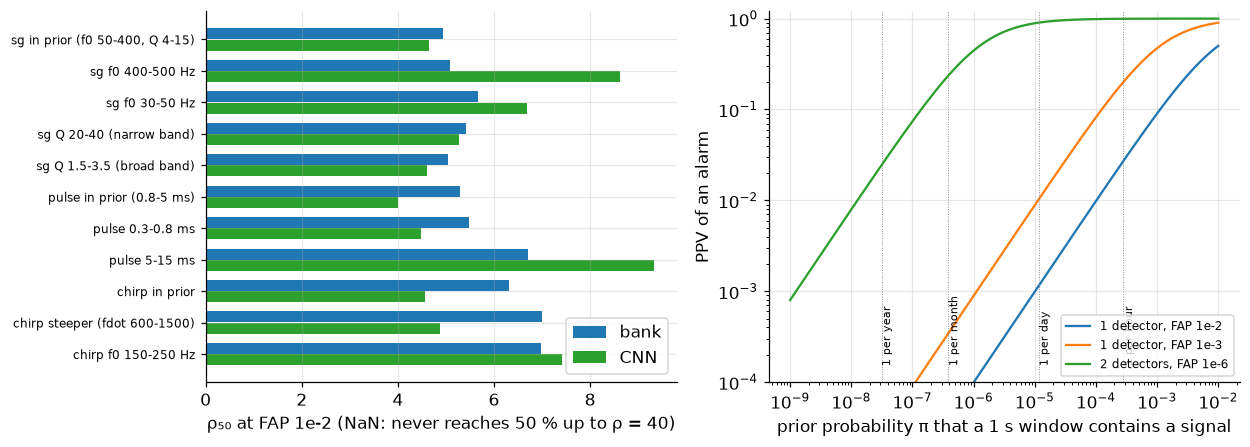

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
names = [c for c in CASES]; y = np.arange(len(names))
ax[0].barh(y - 0.18, P.loc[names, "bank"], height=0.35, color=g.COLORS["freq"], label="bank"); ax[0].barh(y + 0.18, P.loc[names, "cnn"], height=0.35, color="C2", label="CNN")
ax[0].set_yticks(y); ax[0].set_yticklabels(names, fontsize=8); ax[0].invert_yaxis(); ax[0].set_xlabel("ρ₅₀ at FAP 1e-2 (NaN: never reaches 50 % up to ρ = 40)"); ax[0].legend()
pis = np.logspace(-9, -2, 200)
for far, eff, lab in ((1e-2, EPS8["cnn"], "1 detector, FAP 1e-2"), (1e-3, 0.9 * EPS8["cnn"], "1 detector, FAP 1e-3"), (1e-6, 0.8, "2 detectors, FAP 1e-6")):
    ax[1].loglog(pis, ppv(eff, far, pis), label=lab)
for rname, pi in RATES.items(): ax[1].axvline(pi, color="grey", lw=.6, ls=":"); ax[1].text(pi, 1.5e-4, rname, rotation=90, fontsize=7, va="bottom")
ax[1].set_xlabel("prior probability π that a 1 s window contains a signal"); ax[1].set_ylabel("PPV of an alarm"); ax[1].set_ylim(1e-4, 1.2); ax[1].legend(fontsize=8)
fig.tight_layout(); g.savefig(fig, "fig20_prior_baserate"); plt.show()
g.save_json(dict(prior_mismatch=A.to_dict("records"), eff8=EPS8, base_rate=BR.to_dict("records")), "20_summary.json")

## Output and next step

`results/20_summary.json`, `figures/fig20_prior_baserate`. Next: injected glitches with known labels and a robust (Student-t) likelihood (extensions 55, 56).